<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" width="240" alt="Query.Farm"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" width="150" alt="VGI"></a>

# How does a result cap change the source mix?

A news search is a capped sample of an index, not a census of reporting. We will query the real news worker, remove exact repeated URLs, count provider-reported domains, and measure how concentrated those returned results are. The focused experiment expands the prefix of one fixed response from 20 to 50 rows.

The default replays a **real public GDELT response**, captured unchanged through the actual worker on **2026-11-14 at 09:04:19 UTC**. It contains 84 rows for `climate`, with `timespan=1d`, `DateDesc`, and `maxrecords=100`. Every recorded index timestamp is tied, so response order within that tie is not a recency or relevance ranking. The replay preserves that order; it serves a shorter prefix when requested. [Instructions and provenance](README.md).

## Set one result cap

`ROW_LIMIT` is an integer **1–100**, counting raw provider rows before local URL deduplication. Default 20; experiment 50. Replay has at most 84 recorded rows and returns fewer when the cap is larger. `DATA_MODE` accepts replay or live. The query stays `climate`, the provider GDELT, and the requested relative window one day. Restart and run all after editing.

The controlled experiment uses replay. A live rerun queries a moving index and is not the same-sample experiment: its one-day lookback is relative to that request, not to the recording’s clock.

In [1]:
DATA_MODE = "replay"  # "live" uses public GDELT; no fallback.
ROW_LIMIT = 20  # Raw row cap; experiment: 50.

In [2]:
import haybarn
import matplotlib.pyplot as plt
from IPython.display import display

from notebook_support import chart, cleanup, configure, prose, theme

server, thread, previous, provenance, run_utc = configure(DATA_MODE, ROW_LIMIT)
theme()
connection = haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.displaylimit = 16
%sql connection

/Users/rusty/Development/notebook-rollout/full-rollout/checkouts/lane-2/vgi-news/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:339: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of ':variable' with '\:variable' and
/Users/rusty/Development/notebook-rollout/full-rollout/checkouts/lane-2/vgi-news/notebooks/.venv/lib/python3.14/site-packages/sql/parse.py:369: SyntaxWarning: "\:" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\:"? A raw string is also an option.
  Given a query, replaces all occurrences of 'example'[x:y] with 'example'[x\:y].


Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/lane-2/vgi-news/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/lane-2/vgi-news/notebooks/pyproject.toml.

In [3]:
source_label = (
    "Public GDELT recording, captured " + provenance["response_received_utc"]
    if DATA_MODE == "replay"
    else "Live GDELT response; moving one-day query"
)
prose(
    f"**{DATA_MODE.upper()}** • {source_label}. Run started **{run_utc}**. "
    "The displayed window is the provider's requested lookback; "
    "returned index timestamps may cover a much smaller interval. "
    "A matching article may use another meaning of climate; "
    "no relevance, truthfulness or sentiment judgment is inferred."
)

**REPLAY** • Public GDELT recording, captured 2026-11-14T09:04:19.644329+00:00. Run started **2026-11-14T09:08:45.487532+00:00**. The displayed window is the provider's requested lookback; returned index timestamps may cover a much smaller interval. A matching article may use another meaning of climate; no relevance, truthfulness or sentiment judgment is inferred.

## Connect and materialize a single capped search

The literal Git command runs the unchanged worker from a public immutable revision with published pinned SDK dependencies. Replay points its supported base-URL hooks at a strict loopback server. Live clears both provider URL overrides. This example uses no NewsAPI key and does not call that paid provider.

`page_size=100` and `count≤100` keep the search within one requested response, avoiding GDELT’s approximate older-window paging. The result is materialized before display so DataFrame capture cannot repeat the API search.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'news' (TYPE vgi,
    LOCATION 'uvx --python 3.13 --from git+https://github.com/Query-farm/vgi-news@9df0eb1c2480b0b791501f053c7e1be35d2a7e19 --with vgi-python==0.51.0 --with vgi-rpc==0.53.1 --with pyarrow==26.0.1 --with httpx==0.28.1 vgi-news-worker');
SET TimeZone='UTC';
CREATE TABLE settings AS SELECT {{ ROW_LIMIT }}::INTEGER AS row_limit;
CREATE TABLE returned AS
SELECT * FROM news.main.news_search('climate', provider:='gdelt',count:={{ ROW_LIMIT }},page_size:=100,timespan:='1d');
SELECT count(*) AS returned_rows,count(url) AS known_urls,
       count(*) FILTER(WHERE seendate IS NULL) AS missing_index_times,
       min(seendate AT TIME ZONE 'UTC') AS earliest_index_time_utc,max(seendate AT TIME ZONE 'UTC') AS latest_index_time_utc,
       count(DISTINCT seendate) AS distinct_index_times,
       count(tone) AS available_tone_values FROM returned;

Running query in 'DuckDBPyConnection'

1 rows affected.

20 rows affected.

,returned_rows,known_urls,missing_index_times,earliest_index_time_utc,latest_index_time_utc,distinct_index_times,available_tone_values
0,20,20,0,2026-11-13 18:00:00,2026-11-13 18:00:00,1,0


## Count exact URLs before counting domains

The deduplication key is the **exact nonempty URL**. No tracking-query removal, hostname normalization, registrable-domain grouping or syndicated-story clustering is implied. Repeated URL rows are reduced deterministically, keeping the latest known index time and using domain/title as tie breakers. Missing URLs are counted but excluded from article denominators. Empty or missing domains remain an explicit unknown group.

`seendate` is an index timestamp, not necessarily publication time. `tone` is unavailable in the recorded ArtList response; we will not replace it with zero or draw a sentiment chart.

In [5]:
%%sql
CREATE TABLE unique_articles AS
SELECT *,coalesce(nullif(trim(domain),''),'[unknown domain]') AS domain_group
FROM returned WHERE nullif(trim(url),'') IS NOT NULL
QUALIFY row_number() OVER(PARTITION BY url ORDER BY seendate DESC NULLS LAST,domain NULLS LAST,title NULLS LAST)=1;
CREATE TABLE domains AS
SELECT domain_group,count(*) AS articles FROM unique_articles GROUP BY domain_group;
CREATE TABLE ranked_domains AS
SELECT *,row_number() OVER(ORDER BY articles DESC,domain_group) AS domain_rank,
       100.0*articles/sum(articles) OVER() AS share_percent,
       100.0*sum(articles) OVER(ORDER BY articles DESC,domain_group ROWS UNBOUNDED PRECEDING)/sum(articles) OVER() AS cumulative_percent
FROM domains;
CREATE TABLE diagnostics AS
SELECT (SELECT count(*) FROM returned) AS raw_rows,
       (SELECT count(*) FROM returned WHERE nullif(trim(url),'') IS NULL) AS missing_url_rows,
       (SELECT count(*) FROM returned WHERE nullif(trim(url),'') IS NOT NULL)-(SELECT count(*) FROM unique_articles) AS duplicate_url_rows,
       (SELECT count(*) FROM unique_articles) AS unique_urls,
       (SELECT count(*) FROM domains WHERE domain_group<>'[unknown domain]') AS known_domains,
       (SELECT count(*) FROM unique_articles WHERE domain_group='[unknown domain]') AS unknown_domain_urls,
       (SELECT coalesce(sum(share_percent),0) FROM ranked_domains WHERE domain_rank<=5) AS top_five_share_percent;
SELECT * FROM diagnostics;

Running query in 'DuckDBPyConnection'

20 rows affected.

16 rows affected.

16 rows affected.

1 rows affected.

,raw_rows,missing_url_rows,duplicate_url_rows,unique_urls,known_domains,unknown_domain_urls,top_five_share_percent
0,20,0,0,20,16,0,45.0


In [6]:
%%sql diagnostics_frame <<
SELECT * FROM diagnostics;

Running query in 'DuckDBPyConnection'

In [7]:
%%sql domains_frame <<
SELECT * FROM ranked_domains ORDER BY domain_rank;

Running query in 'DuckDBPyConnection'

In [8]:
d = diagnostics_frame.iloc[0]
prose(
    f"A cap of **{ROW_LIMIT} raw rows** returned **{d.raw_rows:.0f}**, "
    f"leaving **{d.unique_urls:.0f} distinct nonempty URLs** after excluding "
    f"**{d.missing_url_rows:.0f} missing-URL rows** and **{d.duplicate_url_rows:.0f} repeated URL rows**. "
    f"There are **{d.known_domains:.0f} known domain strings** "
    f"and **{d.unknown_domain_urls:.0f} URLs with unknown domain**. "
    f"The five largest domain groups account for **{d.top_five_share_percent:.1f}%** "
    "of unique URLs in this response. "
    "That share describes the returned sample; "
    "it is not a news-market share or five independent confirmations."
)

A cap of **20 raw rows** returned **20**, leaving **20 distinct nonempty URLs** after excluding **0 missing-URL rows** and **0 repeated URL rows**. There are **16 known domain strings** and **0 URLs with unknown domain**. The five largest domain groups account for **45.0%** of unique URLs in this response. That share describes the returned sample; it is not a news-market share or five independent confirmations.

## Compare the largest groups with the long tail

The chart shows up to ten domain groups plus one explicitly aggregated remainder. Every unique URL belongs to exactly one displayed segment. Provider domain strings remain separate, including subdomains; a common owner or syndicated story can therefore appear in multiple groups. Ties are shown alphabetically, not by quality.

In [9]:
%%sql chart_frame <<
SELECT domain_group AS label,articles,domain_rank AS display_order FROM ranked_domains WHERE domain_rank<=10
UNION ALL
SELECT 'All other domain groups',sum(articles),11 FROM ranked_domains WHERE domain_rank>10 HAVING count(*)>0
ORDER BY display_order;

Running query in 'DuckDBPyConnection'

findfont: Failed to find font weight semibold for Arial, now using 700.


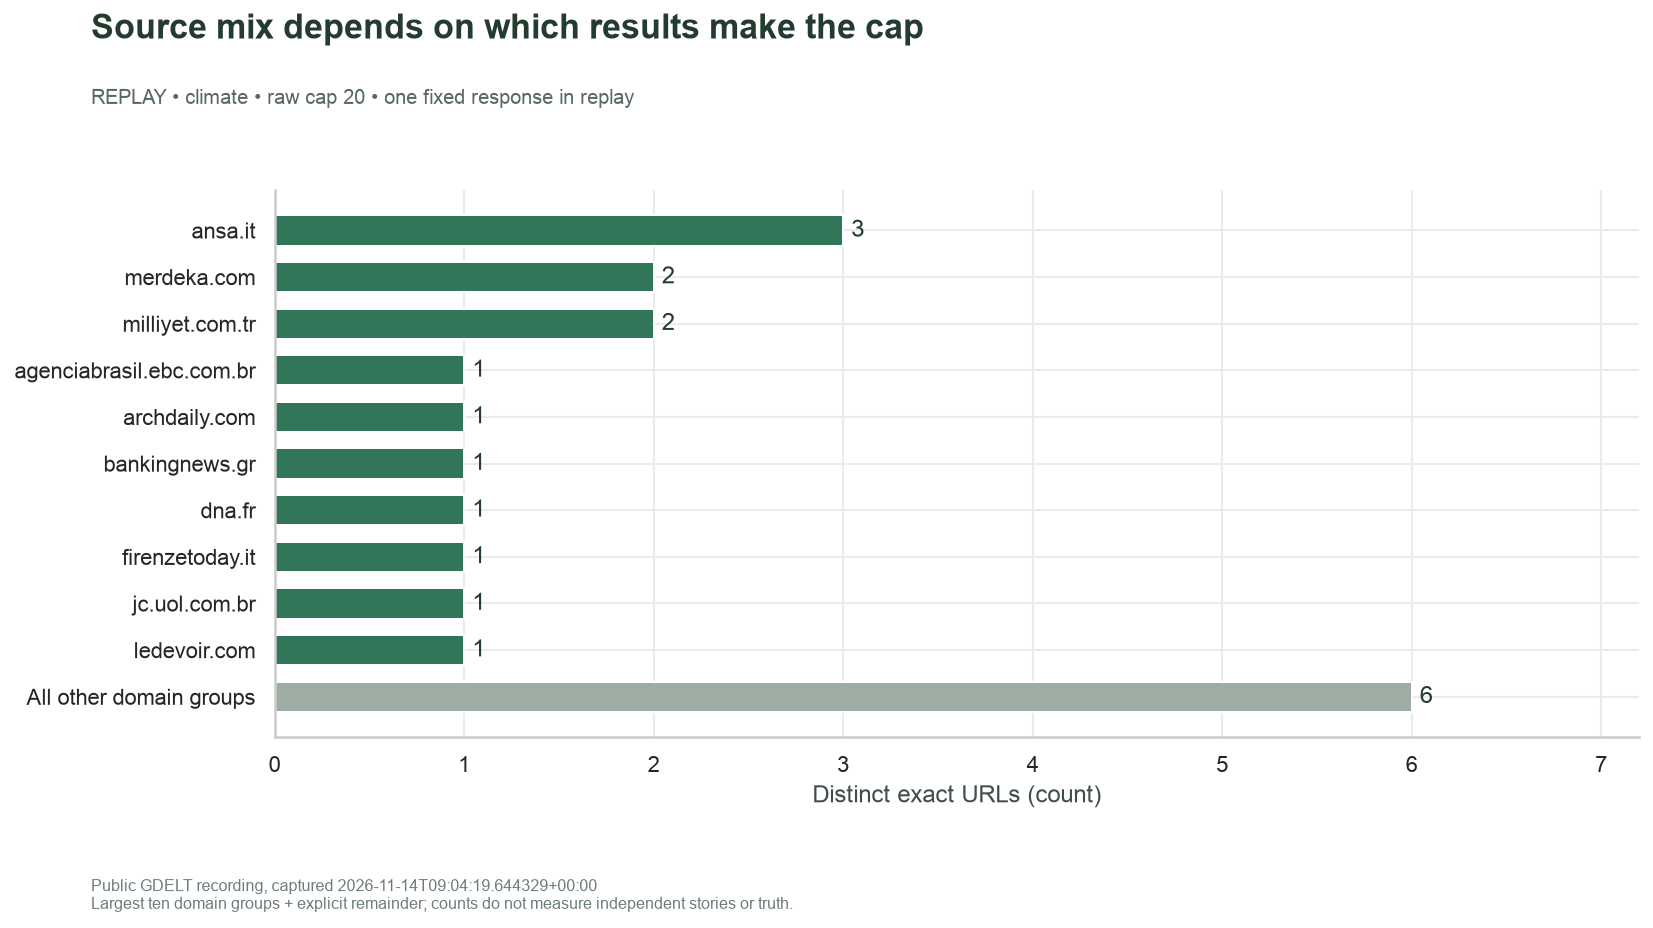

In [10]:
fig, ax = plt.subplots(figsize=(11.8, 6.5))
if chart_frame.empty:
    ax.text(0.5, 0.5, "No nonempty URLs returned", ha="center", transform=ax.transAxes)
    ax.set_axis_off()
else:
    colors = ["#9EADA4" if name == "All other domain groups" else "#327659" for name in chart_frame.label]
    bars = ax.barh(chart_frame.label, chart_frame.articles, color=colors, height=0.65)
    ax.bar_label(bars, padding=4)
    ax.invert_yaxis()
    ax.set(xlabel="Distinct exact URLs (count)", xlim=(0, chart_frame.articles.max() * 1.2))
chart(
    fig,
    "Source mix depends on which results make the cap",
    f"{DATA_MODE.upper()} • climate • raw cap {ROW_LIMIT} • one fixed response in replay",
    source_label
    + "\nLargest ten domain groups + explicit remainder; counts do not measure independent stories or truth.",
)

## Measure concentration without hiding the tail

Sort all domain groups by URL count, then accumulate their shares. The green curve answers how many domain strings are needed to account for a fraction of these exact URLs. The diagonal is an equal-sized-group reference for the same number of groups; it is not a target or statistical confidence band. The unknown group, if present, is included and disclosed above.

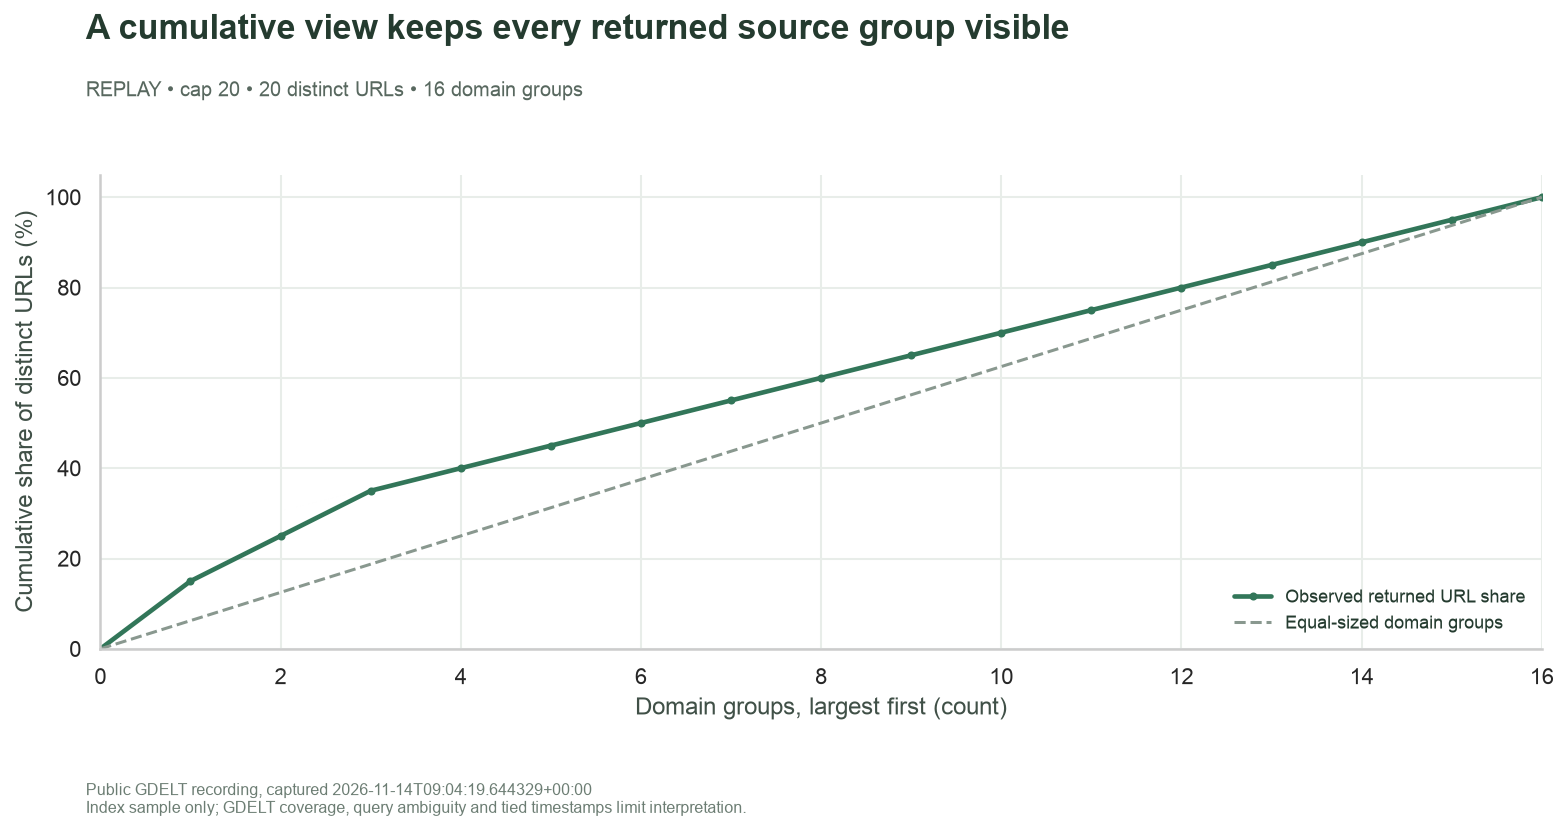

In [11]:
fig, ax = plt.subplots(figsize=(11.2, 5.8))
if domains_frame.empty:
    ax.text(0.5, 0.5, "No domain groups to compare", ha="center", transform=ax.transAxes)
    ax.set_axis_off()
else:
    ax.plot(
        [0, *domains_frame.domain_rank],
        [0, *domains_frame.cumulative_percent],
        color="#327659",
        lw=2.3,
        marker="o",
        ms=3,
        label="Observed returned URL share",
    )
    ax.plot([0, len(domains_frame)], [0, 100], color="#89988F", ls="--", label="Equal-sized domain groups")
    ax.set(
        xlabel="Domain groups, largest first (count)",
        ylabel="Cumulative share of distinct URLs (%)",
        xlim=(0, max(1, len(domains_frame))),
        ylim=(0, 105),
    )
    ax.legend(loc="lower right", fontsize=9)
chart(
    fig,
    "A cumulative view keeps every returned source group visible",
    f"{DATA_MODE.upper()} • cap {ROW_LIMIT} • {d.unique_urls:.0f} distinct URLs "
    f"• {len(domains_frame)} domain groups",
    source_label
    + "\nIndex sample only; GDELT coverage, query ambiguity and tied timestamps limit interpretation.",
)

## Reconcile the sample and its denominators

These checks hold across reasonable caps, including an empty live result. The raw cap applies before deduplication; domain counts partition unique URLs; displayed bars preserve the tail; cumulative shares must be monotone and end at 100% when any URLs are available. We do not assert a particular live count, ranking or source mix.

In [12]:
%%sql checks <<
SELECT 'Raw rows respect the requested cap' AS check_name,
       count(*)<=(SELECT row_limit FROM settings) AS passed FROM returned
UNION ALL SELECT 'Missing plus duplicate plus unique reconciles raw rows',
       missing_url_rows+duplicate_url_rows+unique_urls=raw_rows FROM diagnostics
UNION ALL SELECT 'Distinct URL table has unique nonempty keys',
       count(*)=count(DISTINCT url) AND count(*) FILTER(WHERE nullif(trim(url),'') IS NULL)=0 FROM unique_articles
UNION ALL SELECT 'Domain groups partition unique URLs',
       coalesce((SELECT sum(articles) FROM domains),0)=(SELECT count(*) FROM unique_articles)
UNION ALL SELECT 'Reported groups have positive counts',coalesce(bool_and(articles>0),true) FROM domains
UNION ALL SELECT 'Shares are bounded',coalesce(bool_and(share_percent>0 AND share_percent<=100),true) FROM ranked_domains
UNION ALL SELECT 'Cumulative curve ends at one hundred percent',
       count(*)=0 OR abs(max(cumulative_percent)-100)<1e-8 FROM ranked_domains
UNION ALL SELECT 'Cumulative shares are monotone',coalesce(bool_and(step>=-1e-8),true)
       FROM (SELECT cumulative_percent-lag(cumulative_percent,1,0) OVER(ORDER BY domain_rank) AS step FROM ranked_domains)
UNION ALL SELECT 'All rows came from the selected provider',coalesce(bool_and(source='gdelt'),true) FROM returned
UNION ALL SELECT 'Top-five share is a valid percentage',top_five_share_percent BETWEEN 0 AND 100.00000001 FROM diagnostics
ORDER BY check_name;

Running query in 'DuckDBPyConnection'

In [13]:
display(checks)
assert checks.passed.all(), checks.loc[~checks.passed].to_dict("records")
assert int(chart_frame.articles.sum()) == int(d.unique_urls)
if server:
    assert len(server.requests) == 1
    prose(
        f"**{len(checks)} SQL checks and chart-total reconciliation passed.** "
        "Replay served one validated request from the preserved response prefix."
    )
else:
    prose(
        f"**{len(checks)} SQL checks and chart-total reconciliation passed.** "
        "Live data was used without a replay server."
    )

,check_name,passed
0,All rows came from the selected provider,True
1,Cumulative curve ends at one hundred percent,True
2,Cumulative shares are monotone,True
3,Distinct URL table has unique nonempty keys,True
4,Domain groups partition unique URLs,True
5,Missing plus duplicate plus unique reconciles ...,True
6,Raw rows respect the requested cap,True
7,Reported groups have positive counts,True
8,Shares are bounded,True
9,Top-five share is a valid percentage,True


**10 SQL checks and chart-total reconciliation passed.** Replay served one validated request from the preserved response prefix.

## Focused experiment: expand the preserved prefix

Keep replay mode and change only `ROW_LIMIT` from **20** to **50**. Predict more unique URLs and possibly more domain groups; the top-five share need not move in one direction. Compare those metrics and the cumulative curve. The recording, query, original order and URL key remain fixed, so differences come from admitting more of the same response.

All recorded index timestamps are tied. A different provider tie order could change a short prefix. This experiment therefore illustrates cap sensitivity rather than a chronological trend. Reset to **20**. A live mode change is a separate endpoint check: its moving index cannot reproduce this controlled comparison. Use the separate-output command in the README to preserve the saved default.

In [14]:
connection.close()
cleanup(server, thread, previous)
plt.close("all")

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" width="240" alt="Query.Farm"></a>